In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA,IncrementalPCA
from sklearn.cluster import KMeans,DBSCAN,OPTICS,AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings; warnings.filterwarnings("ignore")
try:
  import umap
  HAS_UMAP=True
except ImportError:
  HAS_UMAP=False
  print("Optional: pip install umap-learn")
np.random.seed(42)

In [2]:
import pandas as pd
df = pd.read_csv("/content/online_retail_II.csv")
print(df.columns.tolist())          # exact names
print(df.head())                    # preview

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS      12.0   
1  489434    79323P                   PINK CHERRY LIGHTS      12.0   
2  489434    79323W                  WHITE CHERRY LIGHTS      12.0   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE       48.0   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX      24.0   

           InvoiceDate  Price  Customer ID         Country  
0  2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1  2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2  2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3  2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4  2009-12-01 07:45:00   1.25      13085.0  United Kingdom  


In [3]:
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nMissing %:\n", (df.isnull().sum() / len(df) * 100).round(2))
print("\nUnique counts:")
for col in df.columns:
    print(f"  {col:<15} → {df[col].nunique():>8,}")

Shape: (247610, 8)

Dtypes:
 Invoice         object
StockCode       object
Description     object
Quantity       float64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
dtype: object

Missing values:
 Invoice            0
StockCode          0
Description     1951
Quantity           1
InvoiceDate        1
Price              1
Customer ID    54230
Country            1
dtype: int64

Missing %:
 Invoice         0.00
StockCode       0.00
Description     0.79
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    21.90
Country         0.00
dtype: float64

Unique counts:
  Invoice         →   14,282
  StockCode       →    4,211
  Description     →    3,937
  Quantity        →      606
  InvoiceDate     →   12,452
  Price           →      989
  Customer ID     →    3,002
  Country         →       32


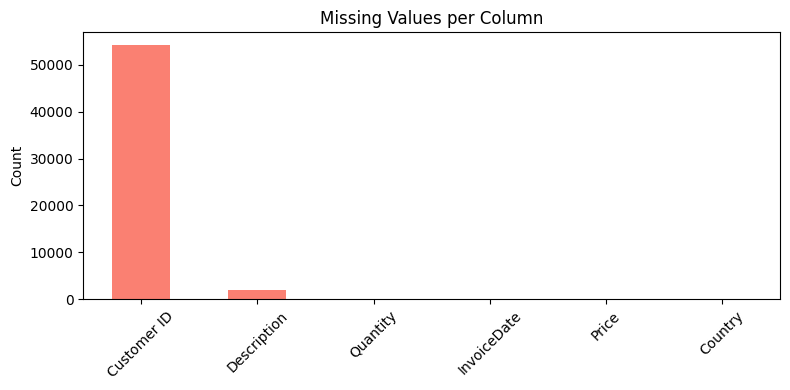

In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    plt.figure(figsize=(8, 4))
    missing.plot(kind="bar", color="salmon")
    plt.title("Missing Values per Column")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values")

In [5]:
print("Raw shape:", df.shape)

# Rename UCI → standard (handles your exact 3 columns)
df = df.rename(columns={
    "Invoice":     "InvoiceNo",       # Invoice → InvoiceNo
    "Price":       "UnitPrice",       # Price   → UnitPrice
    "Customer ID": "CustomerID",      # space   → no space
})

# Verify
required = ["InvoiceNo", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing: {missing}"

# Clean
df = df.dropna(subset=["CustomerID"])                     # drop rows w/o customer
df["CustomerID"] = df["CustomerID"].astype(int)           # float → int (13085.0 → 13085)
df = df[df["Quantity"] > 0]                               # drop returns
df = df[df["UnitPrice"] > 0]                              # drop £0 prices
df["InvoiceNo"] = df["InvoiceNo"].astype(str)             # cast to str
df = df[~df["InvoiceNo"].str.startswith("C")]             # drop cancellations
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])     # parse dates
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]       # line total
df = df[df["UnitPrice"] <= df["UnitPrice"].quantile(0.99)]  # cap 99th pct

print("Clean shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())
print(df.dtypes)

Raw shape: (247610, 8)
Clean shape: (186769, 9)
Unique customers: 2897
InvoiceNo              object
StockCode              object
Description            object
Quantity              float64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              int64
Country                object
TotalPrice            float64
dtype: object


Shape: (186769, 9)

Missing:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64

Skewness:
 Quantity     80.279094
UnitPrice     1.786651
dtype: float64


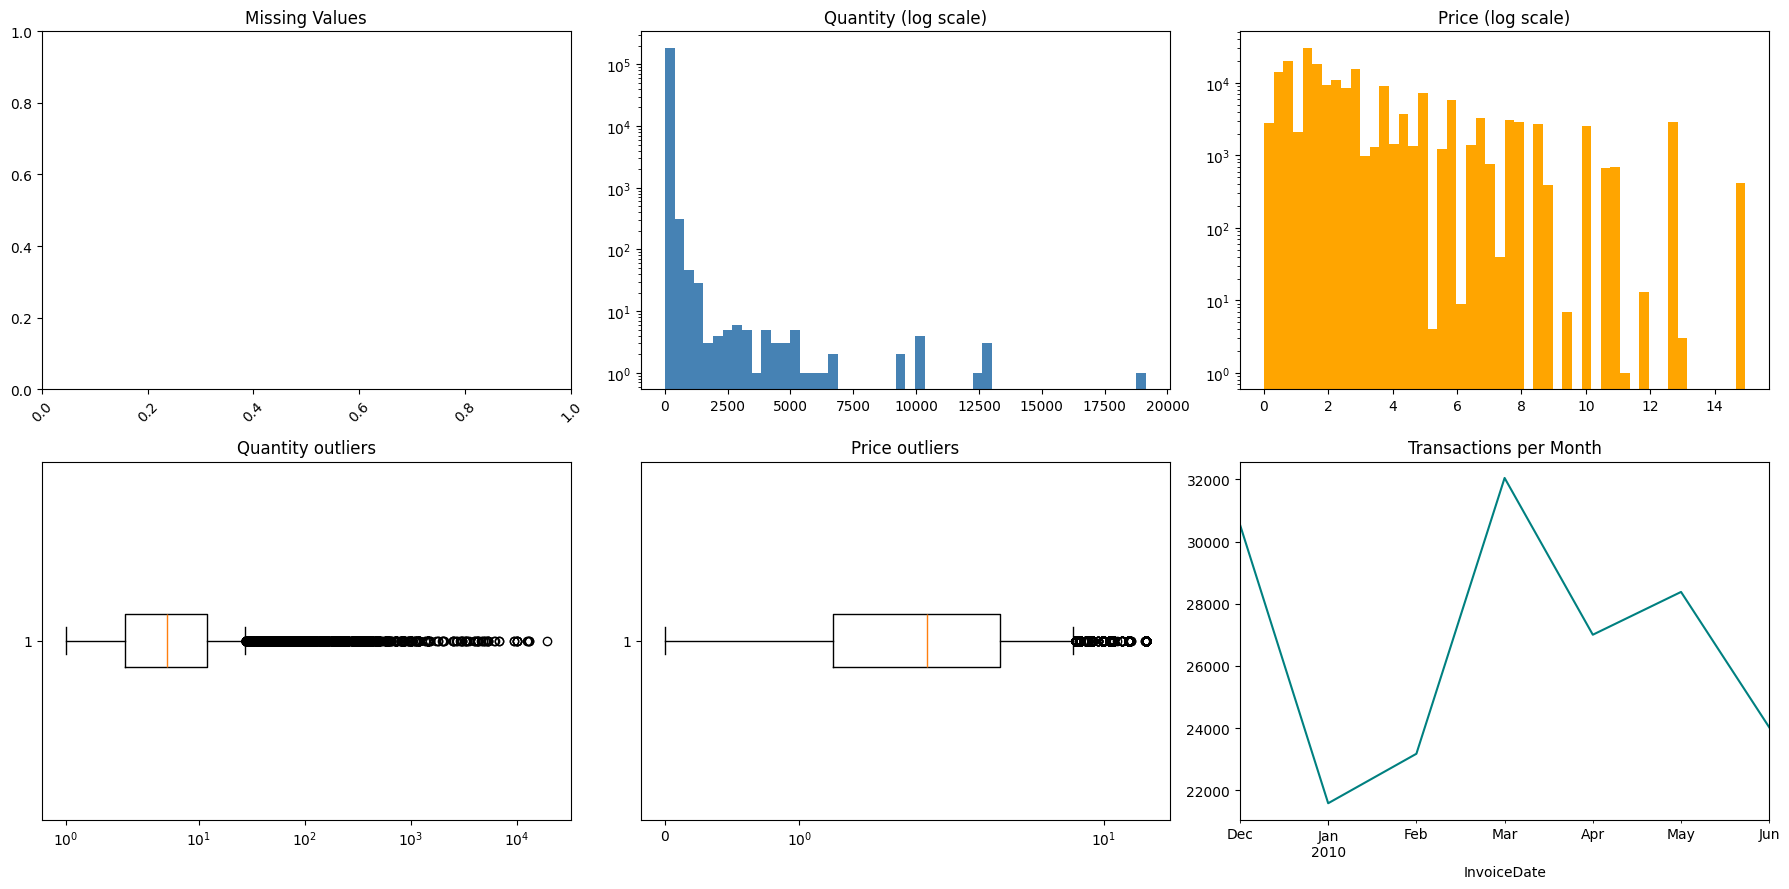

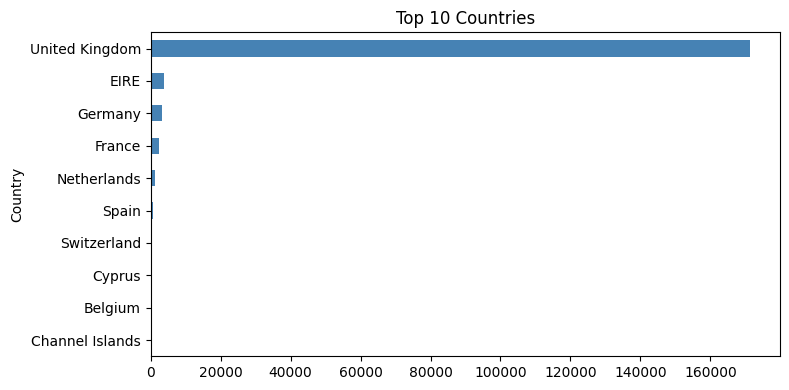

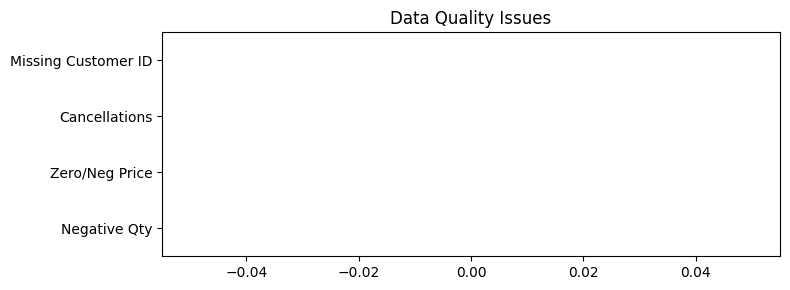

Negative Qty           0
Zero/Neg Price         0
Cancellations          0
Missing Customer ID    0
dtype: int64


In [6]:
# --- Auto-detect column names (works before or after rename) ---
def col(df, *candidates):
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(f"None of {candidates} found. Columns: {df.columns.tolist()}")

PRICE = col(df, "Price", "UnitPrice")               # handle both variants
INV   = col(df, "Invoice", "InvoiceNo")             # handle both variants
CUST  = col(df, "Customer ID", "CustomerID")        # handle both variants

# --- Snapshot ---
print("Shape:", df.shape)
print("\nMissing:\n", df.isnull().sum())
print("\nSkewness:\n", df[[ "Quantity", PRICE ]].skew())

# --- Plots ---
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

miss = df.isnull().sum(); miss = miss[miss > 0].sort_values(ascending=False)
if len(miss):
    axes[0, 0].bar(miss.index, miss.values, color="salmon")
axes[0, 0].set_title("Missing Values"); axes[0, 0].tick_params(axis="x", rotation=45)

axes[0, 1].hist(df["Quantity"].dropna(), bins=50, color="steelblue")
axes[0, 1].set_yscale("log"); axes[0, 1].set_title("Quantity (log scale)")

axes[0, 2].hist(df[PRICE].dropna(), bins=50, color="orange")
axes[0, 2].set_yscale("log"); axes[0, 2].set_title("Price (log scale)")

axes[1, 0].boxplot(df["Quantity"].dropna(), vert=False)
axes[1, 0].set_xscale("symlog"); axes[1, 0].set_title("Quantity outliers")

axes[1, 1].boxplot(df[PRICE].dropna(), vert=False)
axes[1, 1].set_xscale("symlog"); axes[1, 1].set_title("Price outliers")

dates = pd.to_datetime(df["InvoiceDate"], errors="coerce")
dates.dt.to_period("M").value_counts().sort_index().plot(ax=axes[1, 2], color="teal")
axes[1, 2].set_title("Transactions per Month")

plt.tight_layout(); plt.show()

# --- Top 10 countries ---
df["Country"].value_counts().head(10).plot(kind="barh", figsize=(8, 4), color="steelblue")
plt.gca().invert_yaxis(); plt.title("Top 10 Countries"); plt.tight_layout(); plt.show()

# --- Data quality ---
issues = pd.Series({
    "Negative Qty":        (df["Quantity"] < 0).sum(),
    "Zero/Neg Price":      (df[PRICE] <= 0).sum(),
    "Cancellations":       df[INV].astype(str).str.startswith("C").sum(),
    "Missing Customer ID": df[CUST].isnull().sum(),
}).sort_values()
issues.plot(kind="barh", figsize=(8, 3), color="crimson")
plt.title("Data Quality Issues"); plt.tight_layout(); plt.show()
print(issues)

In [7]:
# Reference date = 1 day after the last invoice (so Recency ≥ 1)
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)                          # "today"

rfm = df.groupby("CustomerID").agg(
    Recency   = ("InvoiceDate", lambda x: (reference_date - x.max()).days),              # days since last purchase
    Frequency = ("InvoiceNo", "nunique"),                                                # unique invoices (orders)
    Monetary  = ("TotalPrice", "sum"),                                                   # total spend
).reset_index()

rfm = rfm[rfm["Monetary"] > 0]                                                           # drop non-spenders
rfm["AOV"] = rfm["Monetary"] / rfm["Frequency"]                                          # avg order value

print(rfm.describe())                                                                    # sanity check

         CustomerID      Recency    Frequency       Monetary           AOV
count   2897.000000  2897.000000  2897.000000    2897.000000   2897.000000
mean   15369.531584    66.692786     3.064550    1376.788882    372.456638
std     1681.399297    56.429014     4.808377    5430.020872    455.976248
min    12346.000000     1.000000     1.000000       1.300000      1.300000
25%    13931.000000    18.000000     1.000000     251.590000    173.786667
50%    15371.000000    50.000000     2.000000     523.650000    288.050000
75%    16830.000000   100.000000     3.000000    1175.990000    424.130000
max    18287.000000   206.000000    76.000000  169557.290000  10877.180000


In [8]:
# Log: reduce right-skew from high spenders
rfm["Frequency_log"] = np.log1p(rfm["Frequency"])                                        # log freq
rfm["Monetary_log"]  = np.log1p(rfm["Monetary"])                                         # log spend
rfm["AOV_log"]       = np.log1p(rfm["AOV"])                                              # log AOV

# Standardize: all features weigh equally
X = rfm[["Recency", "Frequency_log", "Monetary_log", "AOV_log"]]                         # feature matrix
X_scaled = StandardScaler().fit_transform(X)                                             # fit + transform

print("Scaled shape:", X_scaled.shape)                                                   # verify

Scaled shape: (2897, 4)


In [9]:
# PCA to 95% variance
pca  = PCA(n_components=0.95, random_state=42)                                           # keep 95% info
X_pca = pca.fit_transform(X_scaled)                                                      # fit
print("PCA kept:", X_pca.shape[1], "components")                                         # how many?
print("Variance explained:", pca.explained_variance_ratio_)                              # per-PC

# 2D PCA for plotting
X_pca2 = PCA(n_components=2, random_state=42).fit_transform(X_scaled)                    # 2D

# Incremental PCA — same result, batched
X_ipca = IncrementalPCA(n_components=2, batch_size=1000).fit_transform(X_scaled)         # batched

PCA kept: 3 components
Variance explained: [0.60076513 0.2496901  0.14885715]


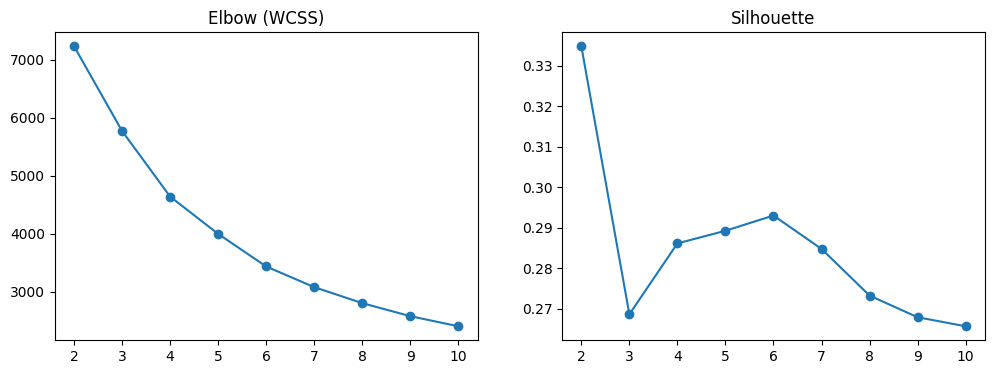

Best k: 2
kmeans_cluster
0    1592
1    1305
Name: count, dtype: int64


In [10]:
# Loop k = 2..10, record WCSS and silhouette
inertias, sils = [], []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)                                # init
    labels = km.fit_predict(X_scaled)                                                    # fit
    inertias.append(km.inertia_)                                                         # WCSS
    sils.append(silhouette_score(X_scaled, labels))                                      # silhouette

# Plot both
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 11), inertias, marker="o"); ax[0].set_title("Elbow (WCSS)")
ax[1].plot(range(2, 11), sils, marker="o");     ax[1].set_title("Silhouette")
plt.show()

best_k = 2 + int(np.argmax(sils))                                                        # best k
print("Best k:", best_k)                                                                 # print

# Fit final model
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)                           # init
rfm["kmeans_cluster"] = kmeans.fit_predict(X_scaled)                                     # assign
print(rfm["kmeans_cluster"].value_counts())                                              # sizes

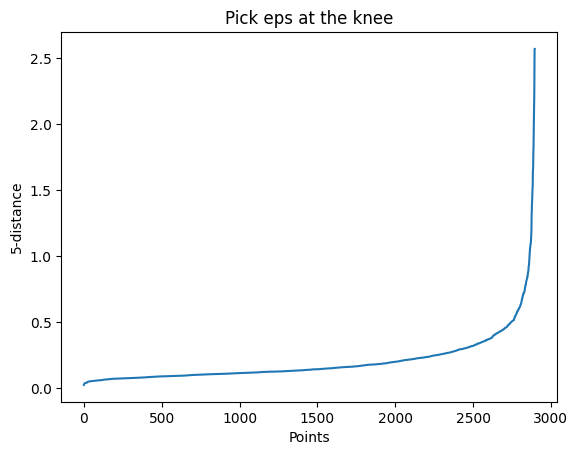

dbscan_cluster
-1      48
 0    1244
 1    1593
 2       7
 3       5
Name: count, dtype: int64
optics_cluster
-1      1502
 0         8
 1         6
 2         5
 3         5
        ... 
 162       7
 163       6
 164       7
 165       7
 166       8
Name: count, Length: 168, dtype: int64


In [11]:
# k-distance plot to pick eps
nbrs = NearestNeighbors(n_neighbors=5).fit(X_scaled)                                     # build index
distances, _ = nbrs.kneighbors(X_scaled)                                                 # query
plt.plot(np.sort(distances[:, -1]))                                                      # plot kth-dist
plt.xlabel("Points"); plt.ylabel("5-distance")
plt.title("Pick eps at the knee"); plt.show()                                            # visually pick

# DBSCAN
rfm["dbscan_cluster"] = DBSCAN(eps=0.7, min_samples=5).fit_predict(X_scaled)             # fit
print(rfm["dbscan_cluster"].value_counts().sort_index())                                 # -1 = noise

# OPTICS
rfm["optics_cluster"] = OPTICS(min_samples=5).fit_predict(X_scaled)                      # fit
print(rfm["optics_cluster"].value_counts().sort_index())                                 # counts

Hierarchical silhouette: 0.2967270492430838


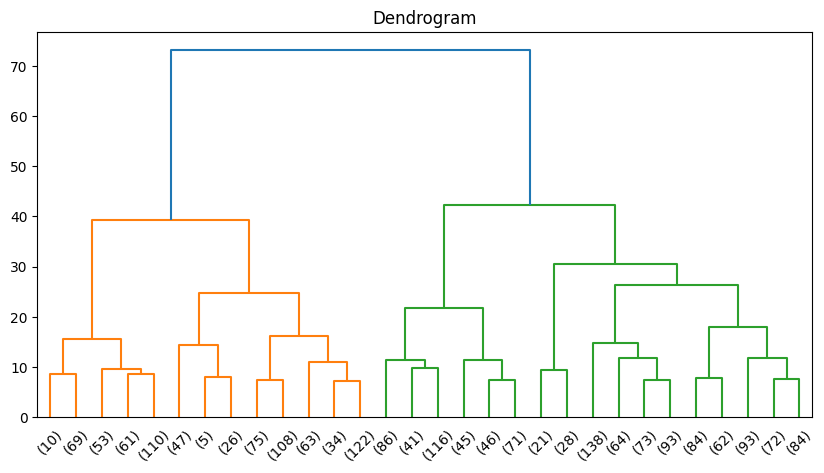

In [12]:
# Sample 2000 rows (Hierarchical is O(n²))
idx = np.random.choice(len(X_scaled), 2000, replace=False)                               # indices
X_hc = X_scaled[idx]                                                                     # sample

hc = AgglomerativeClustering(n_clusters=best_k, linkage="ward")                          # Ward
hc_labels = hc.fit_predict(X_hc)                                                         # fit
print("Hierarchical silhouette:", silhouette_score(X_hc, hc_labels))                     # score

# Dendrogram
plt.figure(figsize=(10, 5))                                                              # figure
dendrogram(linkage(X_hc, method="ward"), truncate_mode="lastp", p=30)                    # draw
plt.title("Dendrogram"); plt.show()                                                      # show

In [13]:
iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=42)             # 2% anomalies
rfm["anomaly"] = iso.fit_predict(X_scaled)                                               # -1 = anomaly
print(rfm["anomaly"].value_counts())                                                     # count

anomaly
 1    2839
-1      58
Name: count, dtype: int64


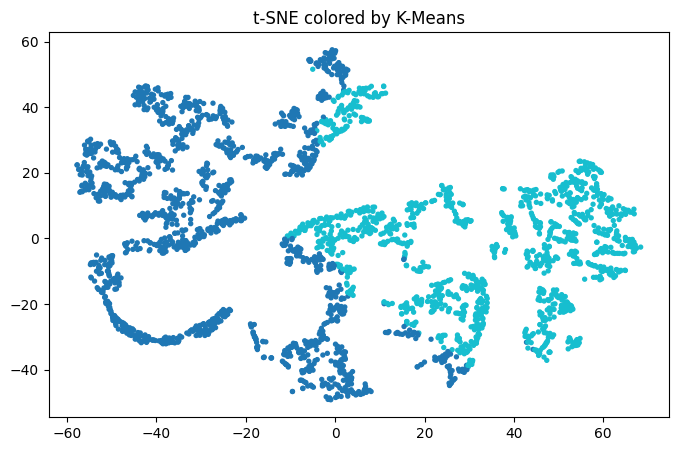

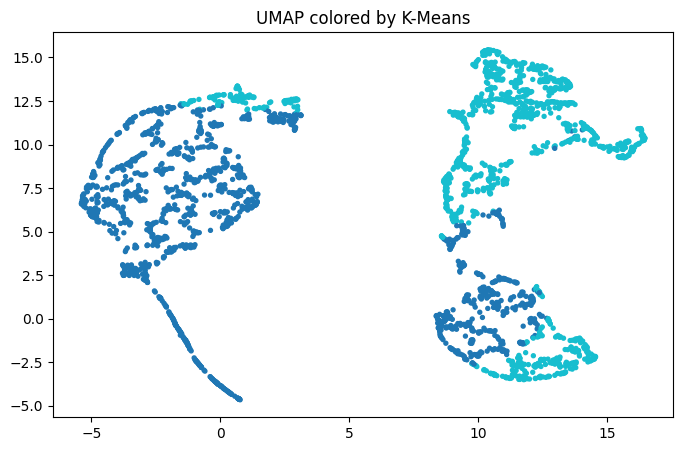

In [14]:
# Sample 5000 (t-SNE slow on 4k+ customers)
idx = np.random.choice(len(X_scaled), min(5000, len(X_scaled)), replace=False)           # indices
X_s = X_scaled[idx]                                                                      # sample
y_s = rfm.iloc[idx]["kmeans_cluster"].values                                             # labels

# t-SNE
X_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(X_s)
plt.figure(figsize=(8, 5))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_s, s=8, cmap="tab10")
plt.title("t-SNE colored by K-Means"); plt.show()

# UMAP (faster, similar result)
if HAS_UMAP:
    X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X_s)               # fit
    plt.figure(figsize=(8, 5))
    plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y_s, s=8, cmap="tab10")                    # scatter
    plt.title("UMAP colored by K-Means"); plt.show()

In [15]:
# Cluster summary
profile = rfm.groupby("kmeans_cluster").agg(
    n_customers  = ("CustomerID", "count"),                                              # count
    avg_recency  = ("Recency", "mean"),                                                  # recency
    avg_freq     = ("Frequency", "mean"),                                                # freq
    avg_monetary = ("Monetary", "mean"),                                                 # spend
    avg_aov      = ("AOV", "mean"),                                                      # AOV
).reset_index()

# Assign personas — adjust thresholds after seeing real numbers
def persona(row):
    if row["avg_monetary"] > 5000 and row["avg_freq"] > 10:                              # top spenders
        return "VIP loyal"
    elif row["avg_recency"] < 30 and row["avg_monetary"] > 500:                          # recent buyers
        return "Recent high-value"
    elif row["avg_monetary"] < 300:                                                      # low-value
        return "Low-value / churn risk"
    else:
        return "Regular"

profile["persona"] = profile.apply(persona, axis=1)                                      # apply
print(profile[["kmeans_cluster", "persona", "n_customers", "avg_monetary"]])

# Save results
import os
os.makedirs("outputs", exist_ok=True)                                                    # create folder
rfm.to_csv("outputs/rfm_clustered.csv", index=False)                                     # save RFM
profile.to_csv("outputs/cluster_personas.csv", index=False)                              # save profiles
print("Saved to:", os.path.abspath("outputs"))                                           # show path

   kmeans_cluster  persona  n_customers  avg_monetary
0               0  Regular         1592    301.559932
1               1  Regular         1305   2688.485808
Saved to: /content/outputs
